# 03 - Exploratory Data Analysis (EDA)
**Project:** Customer Churn Prediction and Recommendation  
**Goal:** Analyze customer behavior, identify churn patterns, and visualize key insights.

In [2]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_dataset

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

DATA_PATH = '../data/indian_netflix_churn_dataset_v2.csv'
df = load_dataset("E:\MCA\SEM 3\Project\Customer_churn_prediction\customer_churn_project\data\indian_netflix_churn_dataset_v2.csv")
print(df.shape)

Loaded: 10,000 rows x 22 columns
(10000, 22)


## 3.1 Demographic Analysis

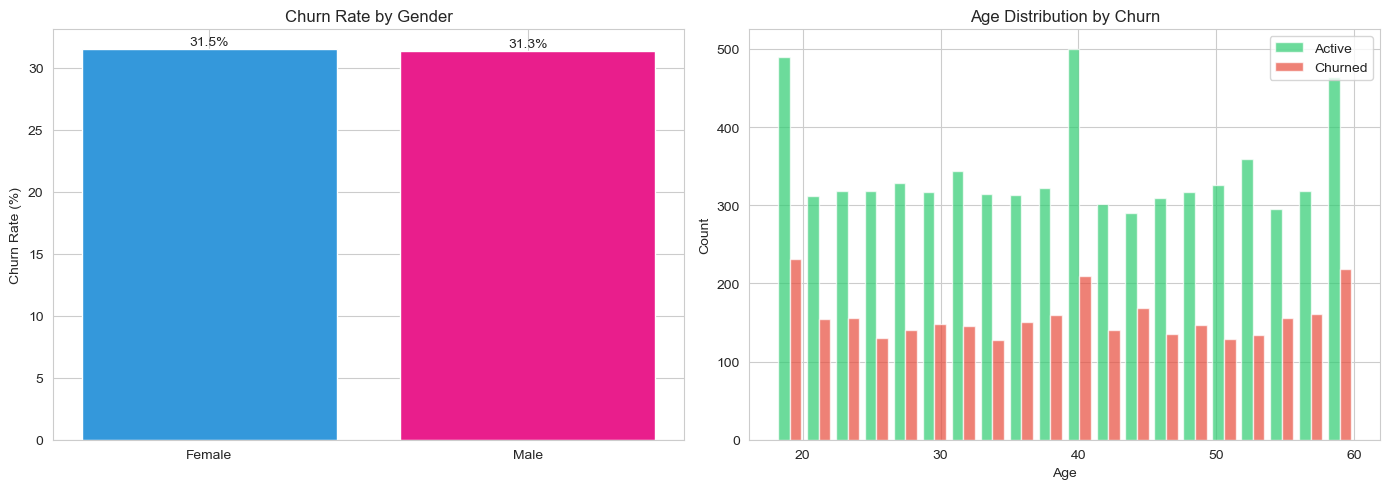

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gender vs Churn
gender_churn = df.groupby('Gender')['Churn'].mean().reset_index()
axes[0].bar(gender_churn['Gender'], gender_churn['Churn'] * 100,
            color=['#3498db', '#e91e8c'])
axes[0].set_title('Churn Rate by Gender')
axes[0].set_ylabel('Churn Rate (%)')
for i, v in enumerate(gender_churn['Churn'] * 100):
    axes[0].text(i, v + 0.3, f'{v:.1f}%', ha='center')

# Age distribution
axes[1].hist([df[df['Churn']==0]['Age'], df[df['Churn']==1]['Age']],
             bins=20, label=['Active', 'Churned'],
             color=['#2ecc71', '#e74c3c'], alpha=0.7)
axes[1].set_title('Age Distribution by Churn')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.savefig('../outputs/eda_demographics.png', dpi=150)
plt.show()

## 3.2 Subscription Plan Analysis

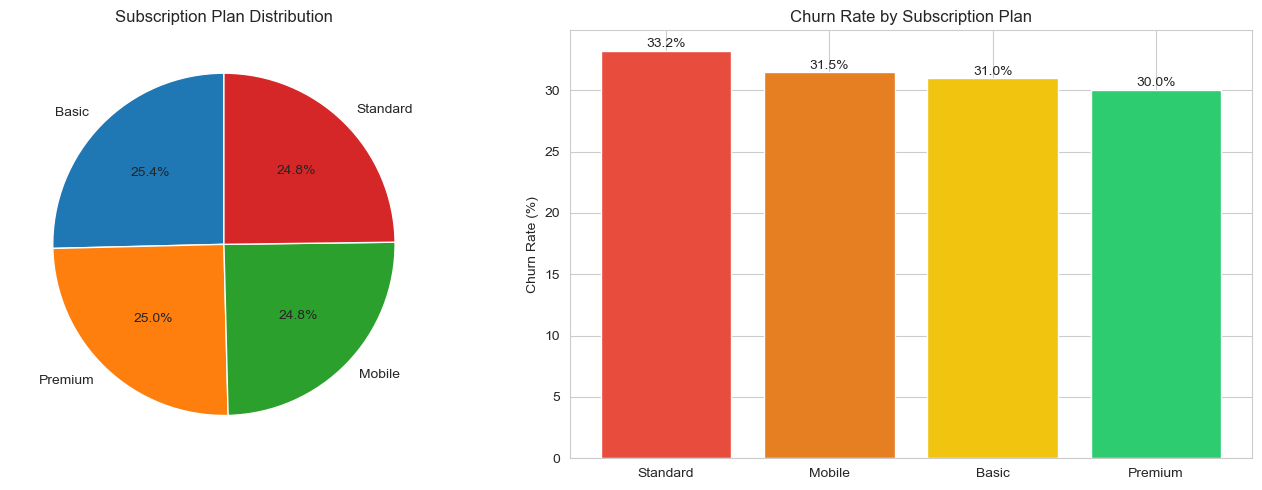

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plan distribution
plan_counts = df['Subscription_Plan'].value_counts()
axes[0].pie(plan_counts.values, labels=plan_counts.index,
            autopct='%1.1f%%', startangle=90)
axes[0].set_title('Subscription Plan Distribution')

# Churn rate by plan
plan_churn = df.groupby('Subscription_Plan')['Churn'].mean().sort_values(ascending=False)
axes[1].bar(plan_churn.index, plan_churn.values * 100,
            color=['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71'])
axes[1].set_title('Churn Rate by Subscription Plan')
axes[1].set_ylabel('Churn Rate (%)')
for i, v in enumerate(plan_churn.values * 100):
    axes[1].text(i, v + 0.3, f'{v:.1f}%', ha='center')

plt.tight_layout()
plt.savefig('../outputs/eda_subscription.png', dpi=150)
plt.show()

## 3.3 Customer Satisfaction vs Churn

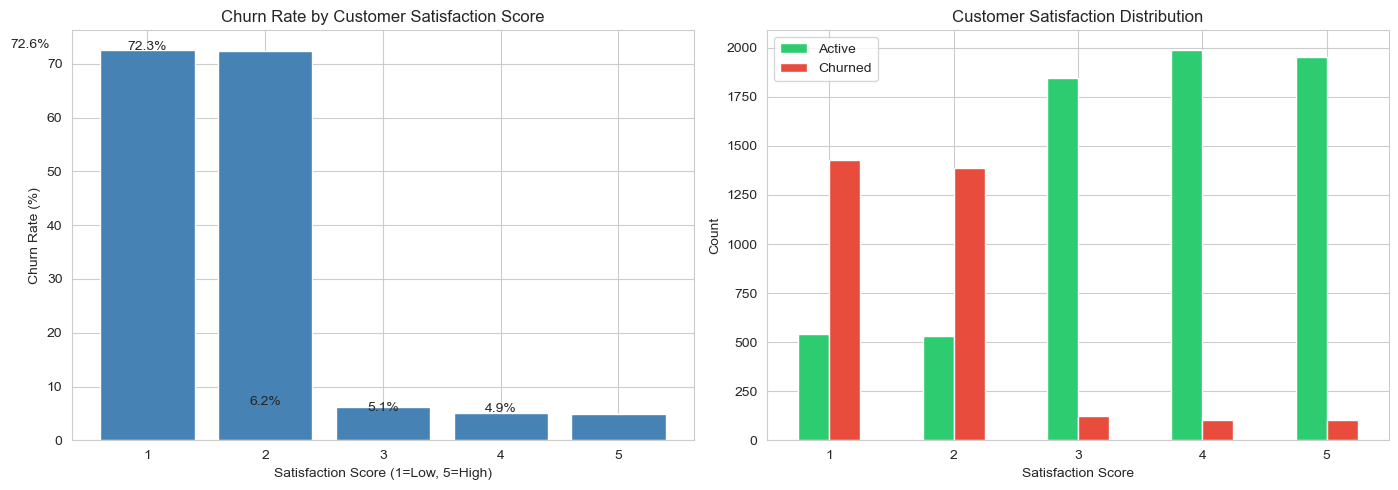

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sat_churn = df.groupby('Customer_Satisfaction')['Churn'].mean()
axes[0].bar(sat_churn.index, sat_churn.values * 100, color='steelblue')
axes[0].set_title('Churn Rate by Customer Satisfaction Score')
axes[0].set_xlabel('Satisfaction Score (1=Low, 5=High)')
axes[0].set_ylabel('Churn Rate (%)')
for i, (idx, v) in enumerate(sat_churn.items()):
    axes[0].text(i, v * 100 + 0.3, f'{v*100:.1f}%', ha='center')

# Satisfaction distribution
sat_counts = df.groupby(['Customer_Satisfaction', 'Churn']).size().unstack()
sat_counts.plot(kind='bar', ax=axes[1], color=['#2ecc71', '#e74c3c'])
axes[1].set_title('Customer Satisfaction Distribution')
axes[1].set_xlabel('Satisfaction Score')
axes[1].set_ylabel('Count')
axes[1].legend(['Active', 'Churned'])
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('../outputs/eda_satisfaction.png', dpi=150)
plt.show()

## 3.4 Support Tickets & Buffering Complaints

C:\Users\Munir Kadiwala\AppData\Local\Temp\ipykernel_24340\3262424971.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(
C:\Users\Munir Kadiwala\AppData\Local\Temp\ipykernel_24340\3262424971.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(


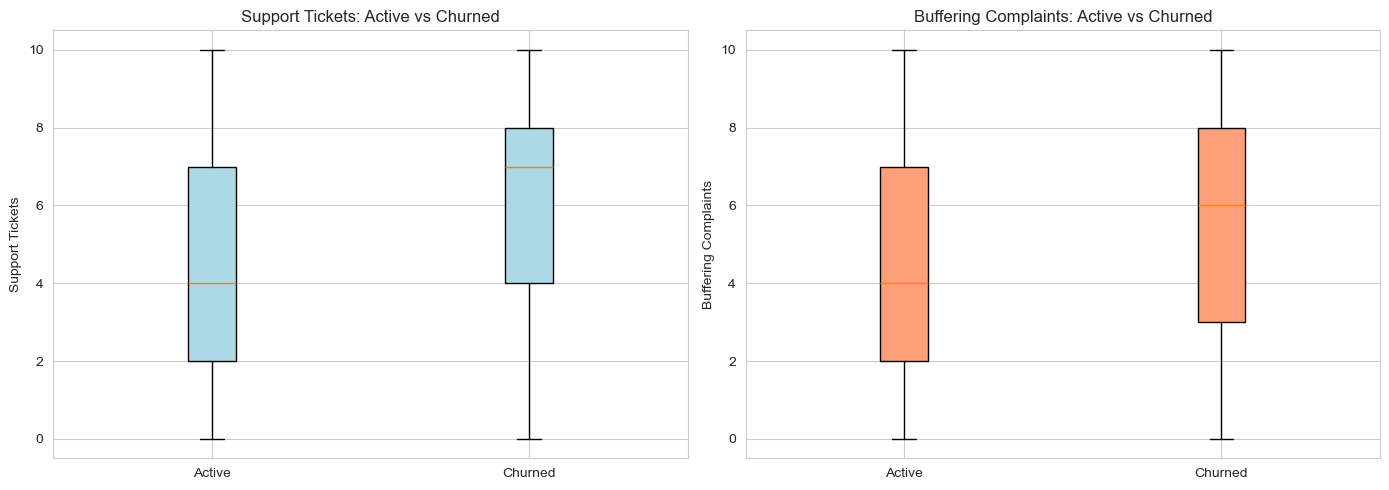

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Support tickets
axes[0].boxplot(
    [df[df['Churn']==0]['Support_Tickets'],
     df[df['Churn']==1]['Support_Tickets']],
    labels=['Active', 'Churned'],
    patch_artist=True,
    boxprops=dict(facecolor='lightblue')
)
axes[0].set_title('Support Tickets: Active vs Churned')
axes[0].set_ylabel('Support Tickets')

# Buffering complaints
axes[1].boxplot(
    [df[df['Churn']==0]['Buffering_Complaints'],
     df[df['Churn']==1]['Buffering_Complaints']],
    labels=['Active', 'Churned'],
    patch_artist=True,
    boxprops=dict(facecolor='lightsalmon')
)
axes[1].set_title('Buffering Complaints: Active vs Churned')
axes[1].set_ylabel('Buffering Complaints')

plt.tight_layout()
plt.savefig('../outputs/eda_complaints.png', dpi=150)
plt.show()

## 3.5 Payment Method & Device Type Analysis

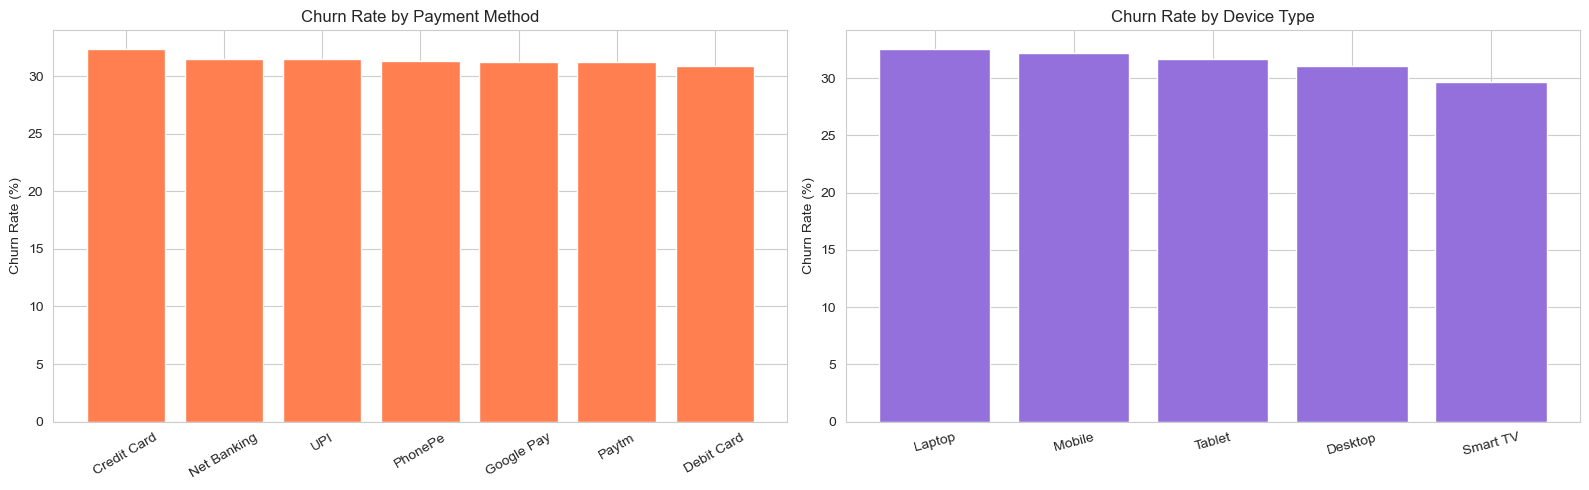

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Payment method churn rate
pm = df.groupby('Payment_Method')['Churn'].mean().sort_values(ascending=False)
axes[0].bar(pm.index, pm.values * 100, color='coral')
axes[0].set_title('Churn Rate by Payment Method')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].tick_params(axis='x', rotation=30)

# Device type churn rate
dt = df.groupby('Device_Type')['Churn'].mean().sort_values(ascending=False)
axes[1].bar(dt.index, dt.values * 100, color='mediumpurple')
axes[1].set_title('Churn Rate by Device Type')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('../outputs/eda_payment_device.png', dpi=150)
plt.show()

## 3.6 Tenure & Watch Hours Analysis

C:\Users\Munir Kadiwala\AppData\Local\Temp\ipykernel_24340\2110085275.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tg = df.groupby('Tenure_Group')['Churn'].mean()


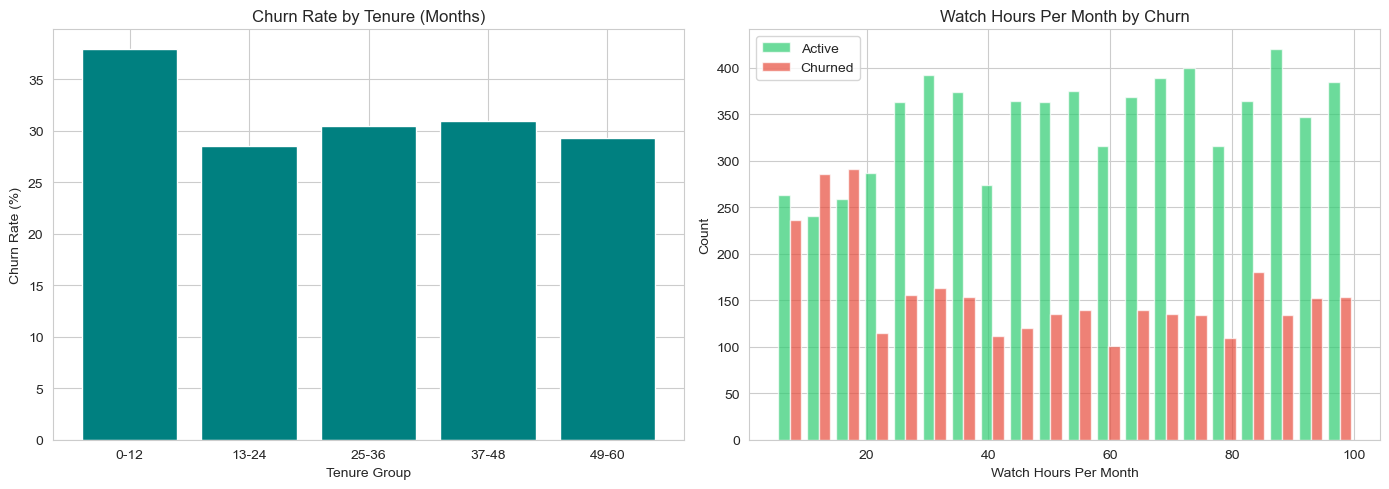

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tenure by churn
df['Tenure_Group'] = pd.cut(df['Tenure_Months'],
                             bins=[0, 12, 24, 36, 48, 60],
                             labels=['0-12', '13-24', '25-36', '37-48', '49-60'])
tg = df.groupby('Tenure_Group')['Churn'].mean()
axes[0].bar(tg.index.astype(str), tg.values * 100, color='teal')
axes[0].set_title('Churn Rate by Tenure (Months)')
axes[0].set_xlabel('Tenure Group')
axes[0].set_ylabel('Churn Rate (%)')

# Watch hours
axes[1].hist([df[df['Churn']==0]['Watch_Hours_Per_Month'],
              df[df['Churn']==1]['Watch_Hours_Per_Month']],
             bins=20, label=['Active', 'Churned'],
             color=['#2ecc71', '#e74c3c'], alpha=0.7)
axes[1].set_title('Watch Hours Per Month by Churn')
axes[1].set_xlabel('Watch Hours Per Month')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.savefig('../outputs/eda_tenure_watch.png', dpi=150)
plt.show()

## 3.7 Top States by Churn

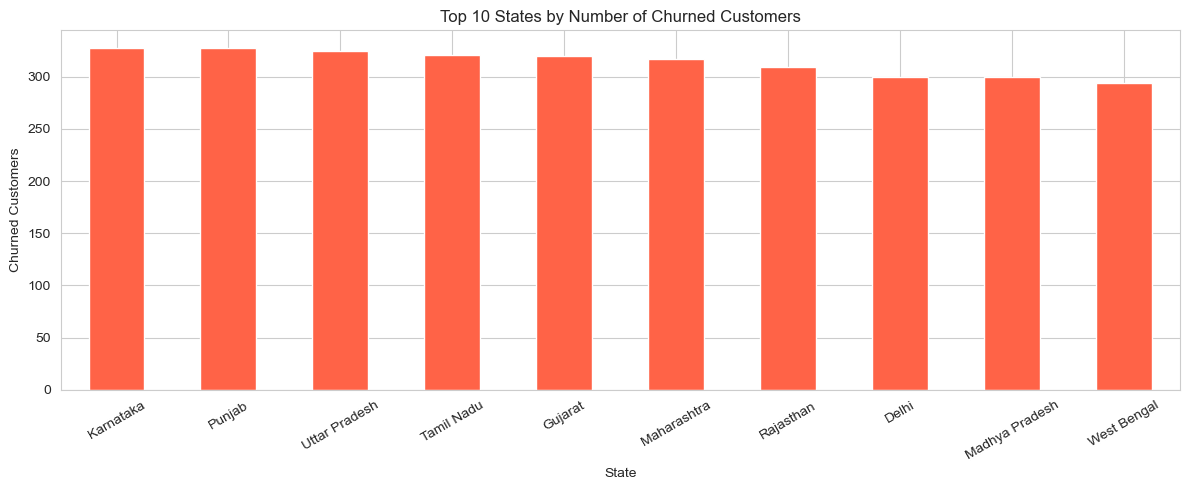

In [9]:
state_churn = df.groupby('State')['Churn'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(12, 5))
state_churn.plot(kind='bar', color='tomato')
plt.title('Top 10 States by Number of Churned Customers')
plt.xlabel('State')
plt.ylabel('Churned Customers')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('../outputs/eda_states.png', dpi=150)
plt.show()

## 3.8 Correlation Heatmap

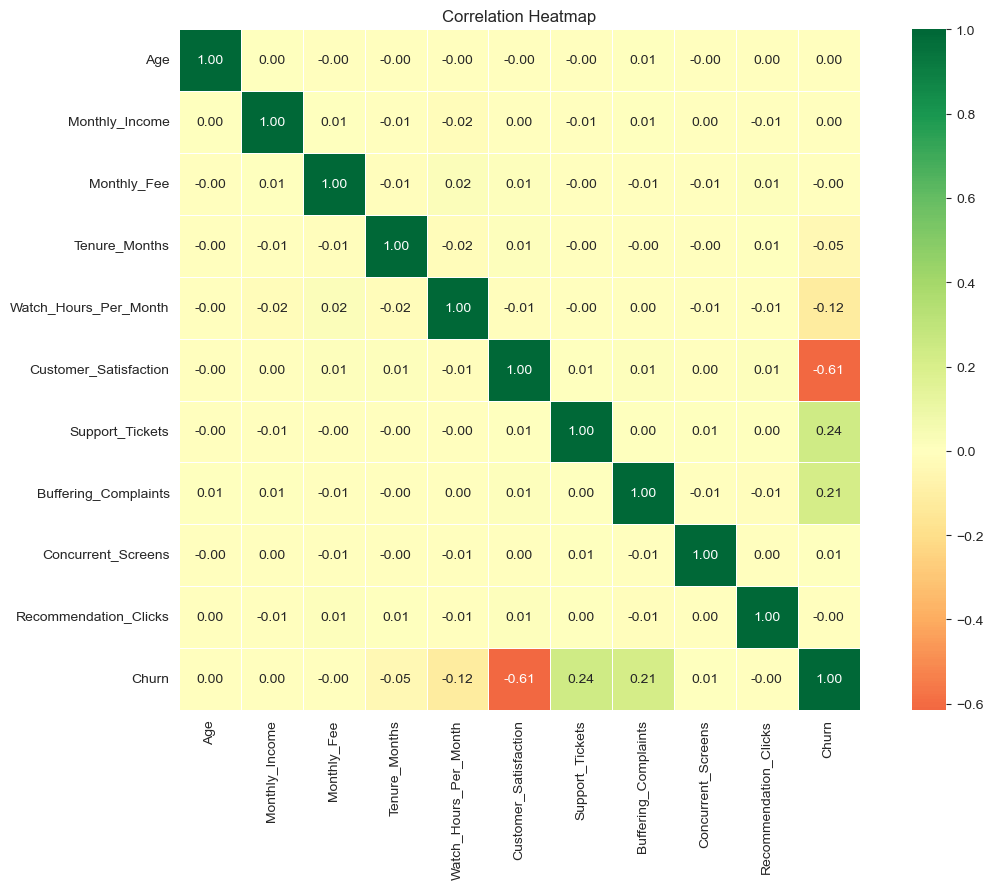

In [10]:
num_cols = ['Age', 'Monthly_Income', 'Monthly_Fee', 'Tenure_Months',
            'Watch_Hours_Per_Month', 'Customer_Satisfaction',
            'Support_Tickets', 'Buffering_Complaints',
            'Concurrent_Screens', 'Recommendation_Clicks', 'Churn']

corr = df[num_cols].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, square=True, linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('../outputs/eda_correlation.png', dpi=150)
plt.show()

## Summary — Key EDA Findings
1. **Satisfaction Score** has the strongest negative correlation with churn — low satisfaction → high churn.
2. **Support Tickets** and **Buffering Complaints** are higher for churned customers.
3. **Tenure** — newer customers churn more; long-term customers tend to stay.
4. **Subscription Plan** — Mobile/Basic plans have higher churn than Premium.
5. **Geographic** — certain states show significantly higher churn counts.
- **Next step:** Notebook 04 — Feature Engineering